<a href="https://colab.research.google.com/github/P-Arun-Kumar/attendance-management-system/blob/main/Example_stress_strain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

# 1. Load and display the first 5 rows
file_path = 'stress_strain_practice.csv'
df = pd.read_csv(file_path)
display(df.head())

# 2. Calculate Stress (MPa) = Force / Area
df['Stress_MPa'] = df['Force_N'] / df['Cross_Section_Area_mm2']

# 3. Calculate Strain (%) = (Elongation / Original_Length) * 100
df['Strain_pct'] = (df['Elongation_mm'] / df['Original_Length_mm']) * 100

# 4. Group results by Material and show average Stress and Strain
material_avg = df.groupby('Material')[['Stress_MPa', 'Strain_pct']].mean().reset_index()
material_avg = material_avg.rename(columns={
    'Stress_MPa': 'Avg_Stress_MPa',
    'Strain_pct': 'Avg_Strain_pct'
})
display(material_avg)

# 5. Identify which material type is strongest (highest average stress)
strongest_idx = material_avg['Avg_Stress_MPa'].idxmax()
strongest_material = material_avg.loc[strongest_idx, 'Material']
max_avg_stress = material_avg.loc[strongest_idx, 'Avg_Stress_MPa']
print(f"The strongest material is {strongest_material} with an average stress of {max_avg_stress:.2f} MPa.")

# 6. Create a summary showing min, max, and average stress for each material
stress_summary = df.groupby('Material')['Stress_MPa'].agg(['min', 'max', 'mean']).reset_index()
stress_summary = stress_summary.rename(columns={
    'min': 'Min_Stress_MPa',
    'max': 'Max_Stress_MPa',
    'mean': 'Avg_Stress_MPa'
})
display(stress_summary)

# 7. Export results to a new CSV file
output_filename = 'stress_strain_processed_results.csv'
df.to_csv(output_filename, index=False)

# Optional: Download file in Google Colab
# from google.colab import files
# files.download(output_filename)

,Test_ID,Material,Force_N,Cross_Section_Area_mm2,Elongation_mm,Original_Length_mm,Test_Date
0,T001,Steel,1749,27,0.51,100,2025-01-01
1,T002,Aluminum,2901,20,0.45,100,2025-01-02
2,T003,Copper,2463,19,0.76,100,2025-01-03
3,T004,Brass,2197,33,0.50,100,2025-01-04
4,T005,Titanium,1312,33,0.45,100,2025-01-05


,Material,Avg_Stress_MPa,Avg_Strain_pct
0,Aluminum,83.776627,0.550000
1,Brass,72.805132,0.535000
2,Copper,107.466696,0.545000
3,Steel,59.954850,0.630000
4,Titanium,65.957533,0.561667


The strongest material is Copper with an average stress of 107.47 MPa.


,Material,Min_Stress_MPa,Max_Stress_MPa,Avg_Stress_MPa
0,Aluminum,42.600000,145.050000,83.776627
1,Brass,44.500000,121.333333,72.805132
2,Copper,48.000000,148.000000,107.466696
3,Steel,43.700000,80.312500,59.954850
4,Titanium,39.757576,96.640000,65.957533


--- First 5 Rows of Cleaned Dataset ---


,Test_ID,Material,Force_N,Cross_Section_Area_mm2,Elongation_mm,Original_Length_mm,Test_Date
0,T001,Steel,1749,27,0.51,100,2025-01-01
1,T002,Aluminum,2901,20,0.45,100,2025-01-02
2,T003,Copper,2463,19,0.76,100,2025-01-03
3,T004,Brass,2197,33,0.50,100,2025-01-04
4,T005,Titanium,1312,33,0.45,100,2025-01-05



--- Average Stress and Strain by Material ---


,Material,Avg_Stress_MPa,Avg_Strain_pct
0,Aluminum,83.776627,0.550000
1,Brass,72.805132,0.535000
2,Copper,107.466696,0.545000
3,Steel,59.954850,0.630000
4,Titanium,65.957533,0.561667


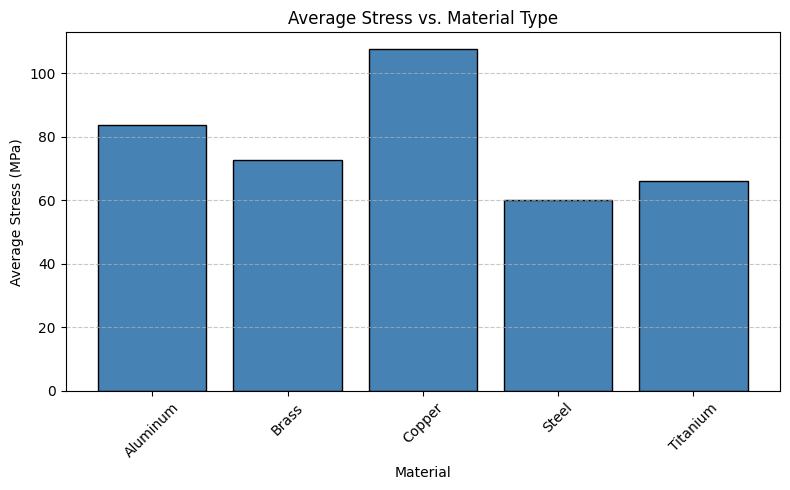


--- Tests Exceeding 200 MPa (0 tests found) ---
No individual tests exceeded 200 MPa.

The strongest material is **Copper** with an average stress of 107.47 MPa.

--- Stress Summary (Min, Max, Avg) by Material ---


,Material,Min_Stress_MPa,Max_Stress_MPa,Avg_Stress_MPa
0,Aluminum,42.600000,145.050000,83.776627
1,Brass,44.500000,121.333333,72.805132
2,Copper,48.000000,148.000000,107.466696
3,Steel,43.700000,80.312500,59.954850
4,Titanium,39.757576,96.640000,65.957533



Processed dataset successfully exported to 'stress_strain_processed_results.csv'.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load data
file_path = 'stress_strain_practice.csv'
df = pd.read_csv(file_path)

# 3. Add error handling for missing values in critical columns
required_cols = ['Force_N', 'Cross_Section_Area_mm2', 'Elongation_mm', 'Original_Length_mm', 'Material']
initial_rows = len(df)
df = df.dropna(subset=required_cols)
if len(df) < initial_rows:
    print(f"Note: Dropped {initial_rows - len(df)} rows due to missing values in critical columns.")

print("--- First 5 Rows of Cleaned Dataset ---")
display(df.head())

# 2. Calculate Stress (MPa) = Force / Area
df['Stress_MPa'] = df['Force_N'] / df['Cross_Section_Area_mm2']

# 3. Calculate Strain (%) = (Elongation / Original_Length) * 100
df['Strain_pct'] = (df['Elongation_mm'] / df['Original_Length_mm']) * 100

# 4. Group results by Material and show average Stress and Strain
material_avg = df.groupby('Material')[['Stress_MPa', 'Strain_pct']].mean().reset_index()
material_avg = material_avg.rename(columns={
    'Stress_MPa': 'Avg_Stress_MPa',
    'Strain_pct': 'Avg_Strain_pct'
})

print("\n--- Average Stress and Strain by Material ---")
display(material_avg)

# 1. Visualization: Plot average stress vs. material type as a bar chart
plt.figure(figsize=(8, 5))
plt.bar(material_avg['Material'], material_avg['Avg_Stress_MPa'], color='steelblue', edgecolor='black')
plt.title('Average Stress vs. Material Type')
plt.xlabel('Material')
plt.ylabel('Average Stress (MPa)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 2. Highlight tests where stress exceeded 200 MPa
high_stress_df = df[df['Stress_MPa'] > 200]
print(f"\n--- Tests Exceeding 200 MPa ({len(high_stress_df)} tests found) ---")

if not high_stress_df.empty:
    # Use pandas styling to highlight rows where Stress_MPa > 200
    def highlight_high_stress(row):
        return ['background-color: #ffcccc' if row['Stress_MPa'] > 200 else '' for _ in row]

    display(df.style.apply(highlight_high_stress, axis=1))
else:
    print("No individual tests exceeded 200 MPa.")

# 5. Identify which material type is strongest (highest average stress)
strongest_idx = material_avg['Avg_Stress_MPa'].idxmax()
strongest_material = material_avg.loc[strongest_idx, 'Material']
max_avg_stress = material_avg.loc[strongest_idx, 'Avg_Stress_MPa']
print(f"\nThe strongest material is **{strongest_material}** with an average stress of {max_avg_stress:.2f} MPa.")

# 6. Create a summary showing min, max, and average stress for each material
stress_summary = df.groupby('Material')['Stress_MPa'].agg(['min', 'max', 'mean']).reset_index()
stress_summary = stress_summary.rename(columns={
    'min': 'Min_Stress_MPa',
    'max': 'Max_Stress_MPa',
    'mean': 'Avg_Stress_MPa'
})

print("\n--- Stress Summary (Min, Max, Avg) by Material ---")
display(stress_summary)

# 7. Export results to a new CSV file
output_filename = 'stress_strain_processed_results.csv'
df.to_csv(output_filename, index=False)
print(f"\nProcessed dataset successfully exported to '{output_filename}'.")